<a href="https://colab.research.google.com/github/KrasnovaOV/A-B-test/blob/main/AB_test_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A/B-тест: анализ результатов и рекомендации для продукта**Гипотеза 2 (по умолчанию): промокод пользователям Android при попытке отмены заказа снижает количество отмен.**Ноутбук универсальный: в блоке «Параметры» переключите `HYPOTHESIS` на `1`, `2` или `3` — фильтры, метрики, статистика, экономика и отчёт пересчитаются автоматически.Структура:1. Загрузка и проверка данных2. Фильтрация под гипотезу, ключевые метрики3. Статистическая значимость: p-value, 95% ДИ разницы, робастные проверки4. Бизнес-значимость: дополнительный доход и ROI5. Графики6. Готовый текст отчёта для продуктовой команды

In [1]:
# 1. ИМПОРТЫ И ПАРАМЕТРЫ
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

HYPOTHESIS = 2          # <- 1, 2 или 3
ALPHA = 0.05
TRAFFIC_PER_MONTH = 100_000     # пользователей в месяц, на которых распространится изменение
REVENUE_PER_ACTION = 150        # руб. с одного успешного целевого действия
IMPLEMENTATION_COST = 50_000    # руб., разовые затраты на внедрение и поддержку
RANDOM_STATE = 42

plt.rcParams['font.family'] = 'DejaVu Sans'   # чтобы кириллица на графиках не превращалась в квадратики

In [2]:
# 2. ЗАГРУЗКА ДАННЫХ
import os

if not os.path.exists('post_abtest_data.csv'):
    try:
        from google.colab import files
        uploaded = files.upload()   # выберите post_abtest_data.csv
    except ImportError:
        raise FileNotFoundError('Положите post_abtest_data.csv рядом с ноутбуком')

df = pd.read_csv('post_abtest_data.csv')
print('Размер датасета:', df.shape)
display(df.head())
print(df.dtypes)

Saving post_abtest_data.csv to post_abtest_data.csv
Размер датасета: (101500, 11)


,user_id,date,app_opened,group,price_seen,order_made,surge,os,user_cancelled,city_center_order,groups
0,867689,2020-05-28,1,Control,1,1,no surge,Android,0.0000,1.0000,Control
1,867689,2020-05-29,1,Control,1,0,surge,iOS,NaN,NaN,Control
2,867689,2020-05-25,1,Control,1,1,surge,Android,0.0000,0.0000,Control
3,752172,2020-05-29,1,Control,1,1,surge,Android,0.0000,1.0000,Control
4,752172,2020-05-28,1,Control,1,1,no surge,iOS,0.0000,0.0000,Control


user_id                int64
date                  object
app_opened             int64
group                 object
price_seen             int64
order_made             int64
surge                 object
os                    object
user_cancelled       float64
city_center_order    float64
groups                object
dtype: object


In [3]:
# 3. ПРОВЕРКА КАЧЕСТВА ДАННЫХ И РАНДОМИЗАЦИИ
print('Пропуски по колонкам:')
print(df.isna().sum().to_string())

# NaN в surge/user_cancelled/city_center_order — это строки без показа цены и без заказа
print('\nСтрок без заказа (order_made == 0):', int((df.order_made == 0).sum()))
print('Из них с непустым user_cancelled:',
      int(df.loc[df.order_made == 0, 'user_cancelled'].notna().sum()))

print('\nРазмер групп:')
print(df.groupby('group').agg(rows=('user_id', 'size'),
                              users=('user_id', 'nunique')).to_string())

# один пользователь не должен попадать в обе группы
mixed = (df.groupby('user_id')['group'].nunique() > 1).sum()
print('\nПользователей в обеих группах:', int(mixed))
print('Период теста:', df.date.min(), '-', df.date.max(), f'({df.date.nunique()} дней)')

# SRM-тест (sample ratio mismatch): соотношение групп не должно отличаться от 50/50
obs = df.groupby('group').size().reindex(['Control', 'Test']).values
srm_p = stats.chisquare(obs, [obs.sum() / 2] * 2).pvalue
print(f'SRM-тест: {obs.tolist()}, p = {srm_p:.4f} -> '
      f'{"распределение корректно" if srm_p > 0.05 else "ВНИМАНИЕ: возможен SRM"}')

Пропуски по колонкам:
user_id                  0
date                     0
app_opened               0
group                    0
price_seen               0
order_made               0
surge                 9142
os                       0
user_cancelled       31343
city_center_order    31343
groups                   0

Строк без заказа (order_made == 0): 31343
Из них с непустым user_cancelled: 0

Размер групп:
          rows  users
group                
Control  50651  12144
Test     50849  12080

Пользователей в обеих группах: 0
Период теста: 2020-05-25 - 2020-05-31 (7 дней)
SRM-тест: [50651, 50849], p = 0.5343 -> распределение корректно


## 3. Фильтрация под гипотезу и расчёт метрик| Гипотеза | Фильтр | Знаменатель | Целевое действие ||---|---|---|---|| 1. Снижение surge | `surge == 'surge'` и `price_seen == 1` | показы цены во время surge | `order_made == 1` (заказ) || 2. Промокод Android | `os == 'Android'`, есть заказ | оформленные заказы | заказ не отменён (`user_cancelled == 0`) || 3. Эмодзи котика | есть заказ, `city_center_order == 0` | заказы не из центра | заказ не отменён |

In [4]:
# 4. ФИЛЬТРАЦИЯ ПОД ВЫБРАННУЮ ГИПОТЕЗУ
def prepare(data, h):
    """Возвращает (отфильтрованные данные, название метрики, описание знаменателя)."""
    if h == 1:
        d = data[(data.surge == 'surge') & (data.price_seen == 1)].copy()
        d['success'] = d['order_made']
        return d, 'Price-to-order конверсия во время surge', 'сессии с показом цены под surge'
    if h == 2:
        d = data[(data.os == 'Android') & (data.order_made == 1)].copy()
        d['success'] = 1 - d['user_cancelled']
        return d, 'Доля сохранённых заказов (Android)', 'оформленные заказы Android'
    if h == 3:
        d = data[(data.order_made == 1) & (data.city_center_order == 0)].copy()
        d['success'] = 1 - d['user_cancelled']
        return d, 'Доля сохранённых заказов (не из центра)', 'заказы не из центра'
    raise ValueError('HYPOTHESIS должен быть 1, 2 или 3')

data, metric_name, denominator = prepare(df, HYPOTHESIS)
print(f'Гипотеза {HYPOTHESIS}: {metric_name}')
print(f'Знаменатель: {denominator}; строк после фильтра: {len(data):,}')
print(f'Доля всего трафика, на который влияет фича: {len(data)/len(df):.1%}')

# Базовая таблица метрик
metrics = data.groupby('group').agg(
    Строк=('success', 'size'),
    Пользователей=('user_id', 'nunique'),
    Успехов=('success', 'sum'),
    Конверсия=('success', 'mean'),
).reindex(['Control', 'Test'])
metrics['Ошибка_среднего'] = np.sqrt(metrics.Конверсия * (1 - metrics.Конверсия) / metrics.Строк)
display(metrics)

# Отдельно: сама метрика отмен (для гипотез 2 и 3)
if HYPOTHESIS in (2, 3):
    cancel = data.groupby('group')['user_cancelled'].agg(Отмен='mean', Отменено='sum')
    display(cancel)

Гипотеза 2: Доля сохранённых заказов (Android)
Знаменатель: оформленные заказы Android; строк после фильтра: 42,177
Доля всего трафика, на который влияет фича: 41.6%


,Строк,Пользователей,Успехов,Конверсия,Ошибка_среднего
group,,,,,
Control,20842,10052,"16,975.0000",0.8145,0.0027
Test,21335,10108,"18,261.0000",0.8559,0.0024


,Отмен,Отменено
group,,
Control,0.1855,"3,867.0000"
Test,0.1441,"3,074.0000"


In [5]:
# 5. СТАТИСТИЧЕСКИЕ ФУНКЦИИ (готовые к переиспользованию)

def wilson_ci(k, n, alpha=ALPHA):
    """95% ДИ для одной конверсии (интервал Уилсона, корректен и на малых долях)."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    z = stats.norm.ppf(1 - alpha / 2)
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

def newcombe_ci(k1, n1, k2, n2, alpha=ALPHA):
    """95% ДИ для РАЗНИЦЫ пропорций (метод Newcombe / hybrid score)."""
    l1, u1 = wilson_ci(k1, n1, alpha)
    l2, u2 = wilson_ci(k2, n2, alpha)
    p1, p2 = k1 / n1, k2 / n2
    d = p2 - p1
    lo = d - np.sqrt((p2 - l2)**2 + (u1 - p1)**2)
    hi = d + np.sqrt((u2 - p2)**2 + (p1 - l1)**2)
    return lo, hi

def cluster_se(d):
    """SE разницы пропорций с поправкой на кластеризацию по user_id
    (один пользователь даёт несколько строк -> строки не независимы)."""
    var = 0.0
    for g in ['Control', 'Test']:
        s = d[d.group == g]
        p = s['success'].mean()
        u = s.groupby('user_id')['success'].agg(['sum', 'count'])
        cl = u['sum'] - p * u['count']
        var += (cl**2).sum() / (u['count'].sum()**2)
    return np.sqrt(var)

def compare_groups(d, n_boot=5000, seed=RANDOM_STATE):
    """Полный тест разницы конверсий: p-value, ДИ, робастные варианты, бутстрэп."""
    res = {}
    for g in ['Control', 'Test']:
        s = d.loc[d.group == g, 'success']
        res[g] = dict(n=int(s.size), k=int(s.sum()), p=float(s.mean()))
    k1, n1, p1 = res['Control']['k'], res['Control']['n'], res['Control']['p']
    k2, n2, p2 = res['Test']['k'], res['Test']['n'], res['Test']['p']

    diff = p2 - p1
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    z = diff / se
    p_value = 2 * stats.norm.sf(abs(z))          # двусторонний z-тест
    p_chi2 = stats.chi2_contingency([[k1, n1 - k1], [k2, n2 - k2]])[1]
    z_crit = stats.norm.ppf(1 - ALPHA / 2)

    se_cl = cluster_se(d)
    p_cluster = 2 * stats.norm.sf(abs(diff / se_cl))

    # кластерный бутстрэп: пересэмплируем пользователей, а не строки
    rng = np.random.default_rng(seed)
    by_user = (d.groupby(['group', 'user_id'])['success'].agg(['sum', 'count'])
                 .reset_index())
    subs = {g: by_user.loc[by_user.group == g, ['sum', 'count']].values
            for g in ['Control', 'Test']}
    boots = np.empty(n_boot)
    for i in range(n_boot):
        vals = {}
        for g, arr in subs.items():
            smp = arr[rng.integers(0, len(arr), len(arr))]
            vals[g] = smp[:, 0].sum() / smp[:, 1].sum()
        boots[i] = vals['Test'] - vals['Control']

    return dict(
        control=res['Control'], test=res['Test'],
        diff=diff, rel_lift=diff / p1,
        se=se, z=z, p_value=p_value, p_chi2=p_chi2,
        ci_wald=(diff - z_crit * se, diff + z_crit * se),
        ci_newcombe=newcombe_ci(k1, n1, k2, n2),
        ci_control=wilson_ci(k1, n1), ci_test=wilson_ci(k2, n2),
        se_cluster=se_cl, p_cluster=p_cluster,
        boot_ci=tuple(np.percentile(boots, [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)])),
        boot_p=float(2 * min((boots <= 0).mean(), (boots >= 0).mean())),
    )

In [6]:
# 6. ЗАПУСК ТЕСТА
r = compare_groups(data)

summary = pd.DataFrame({
    'Control': [r['control']['n'], r['control']['p'], r['ci_control'][0], r['ci_control'][1]],
    'Test': [r['test']['n'], r['test']['p'], r['ci_test'][0], r['ci_test'][1]],
}, index=['Размер выборки', 'Конверсия', 'ДИ 95% (низ)', 'ДИ 95% (верх)'])
display(summary)

print(f"Разница конверсий: {r['diff']*100:+.3f} п.п. (относительный прирост {r['rel_lift']:+.2%})")
print(f"95% ДИ разницы (Wald):     [{r['ci_wald'][0]*100:+.3f}%; {r['ci_wald'][1]*100:+.3f}%]")
print(f"95% ДИ разницы (Newcombe): [{r['ci_newcombe'][0]*100:+.3f}%; {r['ci_newcombe'][1]*100:+.3f}%]")
print(f"95% ДИ разницы (бутстрэп): [{r['boot_ci'][0]*100:+.3f}%; {r['boot_ci'][1]*100:+.3f}%]")
print(f"p-value: z-тест {r['p_value']:.6f} | chi2 {r['p_chi2']:.6f} | "
      f"бутстрэп {r['boot_p']:.6f} | cluster-robust {r['p_cluster']:.6f}")

significant = (r['p_value'] < ALPHA) and (r['ci_wald'][0] > 0)
print('\nВЫВОД: эффект статистически значим' if significant
      else '\nВЫВОД: эффект статистически НЕ значим (или значим в минус)')
print(f"Ширина 95% ДИ: {(r['ci_wald'][1]-r['ci_wald'][0])*100:.3f} п.п. — "
      f"{'узкий интервал, оценка точная' if (r['ci_wald'][1]-r['ci_wald'][0]) < 0.02 else 'интервал широкий, оценка менее точная'}")

,Control,Test
Размер выборки,"20,842.0000","21,335.0000"
Конверсия,0.8145,0.8559
ДИ 95% (низ),0.8091,0.8511
ДИ 95% (верх),0.8197,0.8606


Разница конверсий: +4.146 п.п. (относительный прирост +5.09%)
95% ДИ разницы (Wald):     [+3.438%; +4.853%]
95% ДИ разницы (Newcombe): [+3.438%; +4.853%]
95% ДИ разницы (бутстрэп): [+3.459%; +4.867%]
p-value: z-тест 0.000000 | chi2 0.000000 | бутстрэп 0.000000 | cluster-robust 0.000000

ВЫВОД: эффект статистически значим
Ширина 95% ДИ: 1.415 п.п. — узкий интервал, оценка точная


### Устойчивость результатаПроверяем три вещи:- **Кластеризация:** строки одного пользователя коррелированы, поэтому считаем SE по пользователям (cluster-robust и бутстрэп тоже по пользователям).- **Стабильность по дням:** эффект не должен быть создан одним выбросом/днём.- **Множественные сравнения:** три гипотезы на одном датасете -> поправка Холма.

In [7]:
# 7. СТАБИЛЬНОСТЬ ПО ДНЯМ
daily = (data.groupby(['date', 'group'])['success'].agg(['mean', 'size'])
             .reset_index().pivot(index='date', columns='group', values='mean'))
daily['Разница, п.п.'] = (daily['Test'] - daily['Control']) * 100
display((daily * 100).round(2).assign(**{'Разница, п.п.': daily['Разница, п.п.'].round(2)}))
print(f"Дней с положительным эффектом: {int((daily['Разница, п.п.'] > 0).sum())} из {len(daily)}")

group,Control,Test,"Разница, п.п."
date,,,
2020-05-25,81.8600,84.0400,2.1800
2020-05-26,82.0100,85.8300,3.8200
2020-05-27,80.7600,86.0800,5.3100
2020-05-28,80.7200,85.1700,4.4400
2020-05-29,81.1300,85.9000,4.7700
2020-05-30,81.3800,85.9000,4.5200
2020-05-31,82.2500,86.2400,3.9900


Дней с положительным эффектом: 7 из 7


In [8]:
# 8. МНОЖЕСТВЕННЫЕ СРАВНЕНИЯ (поправка Холма на 3 гипотезы) — для справки\ndef quick_p(h):\n    d, _, _ = prepare(df, h)\n    k = d.groupby('group')['success'].agg(['sum', 'size'])\n    table = [[k.loc['Control', 'sum'], k.loc['Control', 'size'] - k.loc['Control', 'sum']],\n             [k.loc['Test', 'sum'], k.loc['Test', 'size'] - k.loc['Test', 'sum']]]\n    return stats.chi2_contingency(table)[1]\n\ndef holm(pvals):\n    """Поправка Холма: p_(i) * (m - i + 1), с монотонностью."""\n    p = np.asarray(pvals, dtype=float)\n    m = len(p)\n    order = np.argsort(p)\n    adj = np.empty(m)\n    running = 0.0\n    for rank, idx in enumerate(order):\n        val = min(1.0, (m - rank) * p[idx])\n        running = max(running, val)\n        adj[idx] = running\n    return adj\n\npvals = pd.Series({h: quick_p(h) for h in (1, 2, 3)}, name='p_raw').to_frame()\npvals['p_holm'] = holm(pvals.p_raw.values)\ndisplay(pvals.style.format('{:.5f}'))\n\n

## 4. Бизнес-значимостьЛогика расчёта:- дополнительное число целевых действий в месяц = `трафик × прирост конверсии`;- дополнительный доход = `доп. действия × 150 руб.`;- ROI за 1-й месяц = `(доп. доход − 50 000) / 50 000`.Считаем два сценария: изменение на всём трафике (100 000 польз.) и только на целевом сегменте (та доля трафика, которую реально затрагивает фича, — консервативная оценка). Точка считается по точечной оценке эффекта и по нижней границе ДИ.

In [9]:
# 9. ЭКОНОМИКА
def business_case(diff, lo, share, traffic=TRAFFIC_PER_MONTH,
                  rev=REVENUE_PER_ACTION, cost=IMPLEMENTATION_COST):
    rows = []
    scen = [('весь трафик (100%)', 1.0), ('только целевой сегмент', share)]
    for name, mult in scen:
        users = traffic * mult
        for label, delta in [('точечная оценка', diff), ('нижняя граница ДИ', lo)]:
            extra = users * delta
            revenue = extra * rev
            rows.append({
                'Сценарий': name, 'Оценка': label, 'Пользователей': users,
                'Доп_действий_мес': extra, 'Доп_доход_мес_руб': revenue,
                'ROI_1_мес': (revenue - cost) / cost,
            })
    return pd.DataFrame(rows)

share = len(data) / len(df)
biz = business_case(r['diff'], r['ci_newcombe'][0], share)
display(biz.style.format({'Пользователей': '{:,.0f}', 'Доп_действий_мес': '{:,.1f}',
                          'Доп_доход_мес_руб': '{:,.0f}', 'ROI_1_мес': '{:.1%}'}))

best_rev = biz.loc[0, 'Доп_доход_мес_руб']
need = IMPLEMENTATION_COST / REVENUE_PER_ACTION
print(f'Чтобы отбить внедрение, нужно {need:.0f} дополнительных успешных действий '
      f'({IMPLEMENTATION_COST:,.0f} руб. / {REVENUE_PER_ACTION} руб.).')
print(f'При точечной оценке на всём трафике это ~{need / (biz.loc[0, "Доп_действий_мес"] / 30):.1f} дней работы фичи.')
print(f'ROI за 1-й месяц: {(best_rev - IMPLEMENTATION_COST) / IMPLEMENTATION_COST:.1%} '
      f'(чистая прибыль {best_rev - IMPLEMENTATION_COST:,.0f} руб.)')

is_business_significant = (biz.loc[1, 'Доп_доход_мес_руб'] > IMPLEMENTATION_COST)
print('Бизнес-значимость:', 'есть — эффект окупается даже по нижней границе ДИ'
      if is_business_significant else 'под вопросом — нижняя граница ДИ не покрывает затраты')

,Сценарий,Оценка,Пользователей,Доп_действий_мес,Доп_доход_мес_руб,ROI_1_мес
0,весь трафик (100%),точечная оценка,"100,000","4,145.6","621,845",1143.7%
1,весь трафик (100%),нижняя граница ДИ,"100,000","3,438.1","515,720",931.4%
2,только целевой сегмент,точечная оценка,"41,554","1,722.7","258,400",416.8%
3,только целевой сегмент,нижняя граница ДИ,"41,554","1,428.7","214,301",328.6%


Чтобы отбить внедрение, нужно 333 дополнительных успешных действий (50,000 руб. / 150 руб.).
При точечной оценке на всём трафике это ~2.4 дней работы фичи.
ROI за 1-й месяц: 1143.7% (чистая прибыль 571,845 руб.)
Бизнес-значимость: есть — эффект окупается даже по нижней границе ДИ


,чек 100 руб.,чек 150 руб.,чек 200 руб.,чек 300 руб.
"ROI за 1-й месяц, 100% трафика (точечная оценка)",729%,1144%,1558%,2387%


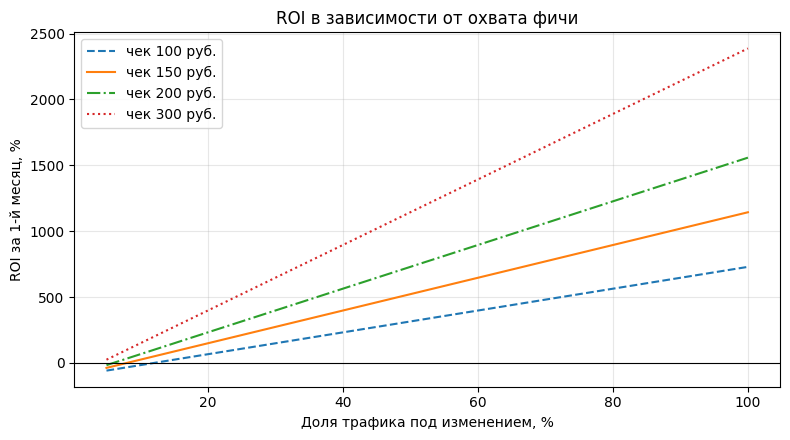

In [10]:
# 10. ЧУВСТВИТЕЛЬНОСТЬ: как меняется ROI при другом чеке и разном охвате
cheques = [100, 150, 200, 300]
sens = pd.DataFrame(
    {f'чек {rev} руб.': [
        (TRAFFIC_PER_MONTH * r['diff'] * rev - IMPLEMENTATION_COST) / IMPLEMENTATION_COST]
     for rev in cheques},
    index=['ROI за 1-й месяц, 100% трафика (точечная оценка)'])
display(sens.style.format('{:.0%}'))

fig, ax = plt.subplots(figsize=(8, 4.5))
shares = np.linspace(0.05, 1.0, 25)
for rev, style in zip(cheques, ['--', '-', '-.', ':']):
    roi = (TRAFFIC_PER_MONTH * shares * r['diff'] * rev - IMPLEMENTATION_COST) / IMPLEMENTATION_COST
    ax.plot(shares * 100, roi * 100, style, label=f'чек {rev} руб.')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('Доля трафика под изменением, %')
ax.set_ylabel('ROI за 1-й месяц, %')
ax.set_title('ROI в зависимости от охвата фичи')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


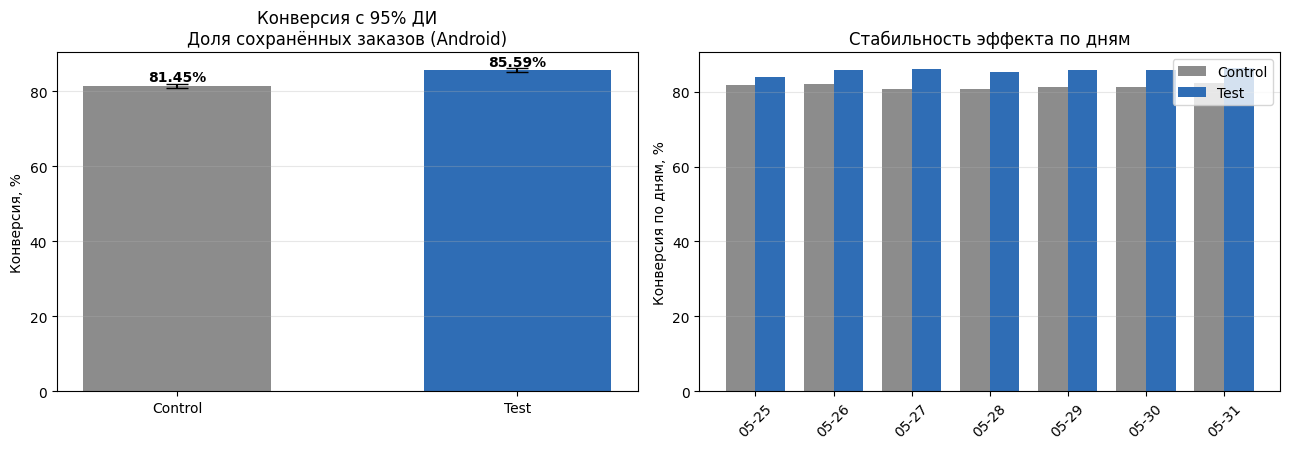

In [11]:
# 11. ГРАФИКИ: конверсии с ДИ и распределение разницы (бутстрэп)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

ax = axes[0]
groups = ['Control', 'Test']
vals = [r['control']['p'], r['test']['p']]
errs = [[vals[0] - r['ci_control'][0], vals[1] - r['ci_test'][0]],
        [r['ci_control'][1] - vals[0], r['ci_test'][1] - vals[1]]]
bars = ax.bar(groups, [v * 100 for v in vals], color=['#8c8c8c', '#2f6db5'], width=0.55)
ax.errorbar(groups, [v * 100 for v in vals], yerr=[[e * 100 for e in errs[0]],
                                                  [e * 100 for e in errs[1]]],
            fmt='none', ecolor='black', capsize=8)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v * 100 + 1.2, f'{v:.2%}', ha='center', fontweight='bold')
ax.set_ylabel('Конверсия, %')
ax.set_title(f'Конверсия с 95% ДИ\n{metric_name}')
ax.grid(axis='y', alpha=0.3)

ax = axes[1]
dates = daily.index
width = 0.38
ax.bar(np.arange(len(dates)) - width/2, daily['Control'] * 100, width, label='Control', color='#8c8c8c')
ax.bar(np.arange(len(dates)) + width/2, daily['Test'] * 100, width, label='Test', color='#2f6db5')
ax.set_xticks(np.arange(len(dates)))
ax.set_xticklabels([d[5:] for d in dates], rotation=45)
ax.set_ylabel('Конверсия по дням, %')
ax.set_title('Стабильность эффекта по дням')
ax.legend(); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Итоговый отчёт для продуктовой командыНиже ячейка собирает текст отчёта из рассчитанных значений — его можно скопировать в шаблон.

In [12]:
# 12. АВТОМАТИЧЕСКИЙ ЧЕРНОВИК ОТЧЁТА
pct = lambda x: f'{x:.2%}'
fmt_p = lambda x: f'{x:.2e}' if x < 0.001 else f'{x:.4f}'
pp = lambda x: f'{x*100:+.2f} п.п.'

reco = ('ВНЕДРЯТЬ' if (significant and is_business_significant) else
        'НЕ ВНЕДРЯТЬ' if not significant else 'ВНЕДРЯТЬ С ОГРАНИЧЕНИЯМИ / ДОП. ТЕСТ')

report = f'''
ГИПОТЕЗА {HYPOTHESIS}: {metric_name}

1. РЕЗУЛЬТАТЫ ТЕСТА
   Control: {r['control']['n']:,} наблюдений, конверсия {pct(r['control']['p'])}
            (95% ДИ {pct(r['ci_control'][0])}–{pct(r['ci_control'][1])})
   Test:    {r['test']['n']:,} наблюдений, конверсия {pct(r['test']['p'])}
            (95% ДИ {pct(r['ci_test'][0])}–{pct(r['ci_test'][1])})
   Разница: {pp(r['diff'])} (относительно {r['rel_lift']:+.1%}),
            95% ДИ [{pp(r['ci_newcombe'][0])}; {pp(r['ci_newcombe'][1])}]
   p-value: {fmt_p(r['p_value'])} (z-тест; chi2 {fmt_p(r['p_chi2'])}; cluster-robust {fmt_p(r['p_cluster'])})
   Значимость: {'эффект статистически значим' if significant else 'эффект НЕ значим на уровне 5%'}

2. ЭКОНОМИЧЕСКОЕ ОБОСНОВАНИЕ
   Прирост конверсии: {pp(r['diff'])}
   Доп. успешных действий в месяц (100 000 польз.): {biz.loc[0, 'Доп_действий_мес']:,.0f}
   Доп. доход в месяц: {biz.loc[0, 'Доп_доход_мес_руб']:,.0f} руб.
   Затраты на внедрение: {IMPLEMENTATION_COST:,.0f} руб. (разово)
   ROI за 1-й месяц: {biz.loc[0, 'ROI_1_мес']:.0%} (чистая выгода {biz.loc[0, 'Доп_доход_мес_руб'] - IMPLEMENTATION_COST:,.0f} руб.)
   Консервативно (нижняя граница ДИ): {biz.loc[1, 'Доп_доход_мес_руб']:,.0f} руб., ROI {biz.loc[1, 'ROI_1_мес']:.0%}

3. РЕКОМЕНДАЦИЯ: {reco}
   {'Эффект одновременно статистически значим и окупает внедрение.' if significant and is_business_significant
     else 'Эффект не проходит одновременно оба фильтра (статистику и экономику).'}

4. СТРАТЕГИЯ ВНЕДРЕНИЯ (если внедряем):
   Шаг 1 — 10% целевой аудитории, 5–7 дней: контроль техметрик (crash rate, latency), проверка
           на отсутствие негативных эффектов (например, рост повторных отмен, падение ARPU на заказ).
   Шаг 2 — 50% аудитории, 1–2 недели: подтверждение эффекта на большей выборке, проверка
           экономики по факту (реальный чек, каннибализация скидок).
   Шаг 3 — 100%: полный rollout, эффект фиксируем в дашборде, A/A-контроль раз в месяц.
   Откат: если на любом шаге эффект < нижней границы ДИ или растут поддерживающие затраты.
'''
print(report)


ГИПОТЕЗА 2: Доля сохранённых заказов (Android)

1. РЕЗУЛЬТАТЫ ТЕСТА
   Control: 20,842 наблюдений, конверсия 81.45%
            (95% ДИ 80.91%–81.97%)
   Test:    21,335 наблюдений, конверсия 85.59%
            (95% ДИ 85.11%–86.06%)
   Разница: +4.15 п.п. (относительно +5.1%),
            95% ДИ [+3.44 п.п.; +4.85 п.п.]
   p-value: 1.58e-30 (z-тест; chi2 1.94e-30; cluster-robust 5.80e-31)
   Значимость: эффект статистически значим

2. ЭКОНОМИЧЕСКОЕ ОБОСНОВАНИЕ
   Прирост конверсии: +4.15 п.п.
   Доп. успешных действий в месяц (100 000 польз.): 4,146
   Доп. доход в месяц: 621,845 руб.
   Затраты на внедрение: 50,000 руб. (разово)
   ROI за 1-й месяц: 1144% (чистая выгода 571,845 руб.)
   Консервативно (нижняя граница ДИ): 515,720 руб., ROI 931%

3. РЕКОМЕНДАЦИЯ: ВНЕДРЯТЬ
   Эффект одновременно статистически значим и окупает внедрение.

4. СТРАТЕГИЯ ВНЕДРЕНИЯ (если внедряем):
   Шаг 1 — 10% целевой аудитории, 5–7 дней: контроль техметрик (crash rate, latency), проверка
           на о